# 02 · Forecast evaluation

Analysis of the walk-forward out-of-sample 15-minute forecasts written by `fr-power train` (`data/processed/predictions.parquet`). Before October 2025 the auction cleared hourly, so the four quarters of an hour share one price. Nothing is retrained here except the single illustrative LightGBM fit at the end.

All models are scored on the same hours (those where every model has a forecast).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from fr_power.config import load_config
from fr_power.data import MTU_15MIN_START
from fr_power.evaluation import (
    common_rows, conformal_intervals, dm_table, mae_by_year, point_metrics,
)
from fr_power.features import TARGET, feature_columns
from fr_power.models import LightGBMForecaster

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

cfg = load_config("../configs/default.yaml")
matrix = pd.read_parquet("../data/processed/feature_matrix.parquet")
predictions = pd.read_parquet("../data/processed/predictions.parquet")
actual = pd.read_parquet("../data/processed/prices_15min.parquet")["price_15min"]
hourly = pd.read_parquet("../data/processed/predictions_hourly.parquet")
df = common_rows(actual, predictions)
print(f"{len(df):,} out-of-sample quarter-hours, {df.index.min():%Y-%m-%d} -> {df.index.max():%Y-%m-%d}")

202,312 out-of-sample quarter-hours, 2020-12-31 -> 2026-11-15


## Headline metrics (EUR/MWh)

`rmae_vs_naive` < 1 means the model beats the naive benchmark.

In [2]:
point_metrics(actual, predictions).round(2)

,mae,rmse,median_ae,rmae_vs_naive
naive,29.40,53.34,16.92,1.00
lasso,24.55,41.10,16.13,0.84
lightgbm,35.68,61.23,19.76,1.21
extra_trees,26.35,43.20,17.35,0.90
ensemble,25.60,42.68,16.53,0.87


## Accuracy over time

Absolute errors scale with the price level, so the crisis years dominate any full-sample average. The relative ranking of models is the more stable signal.

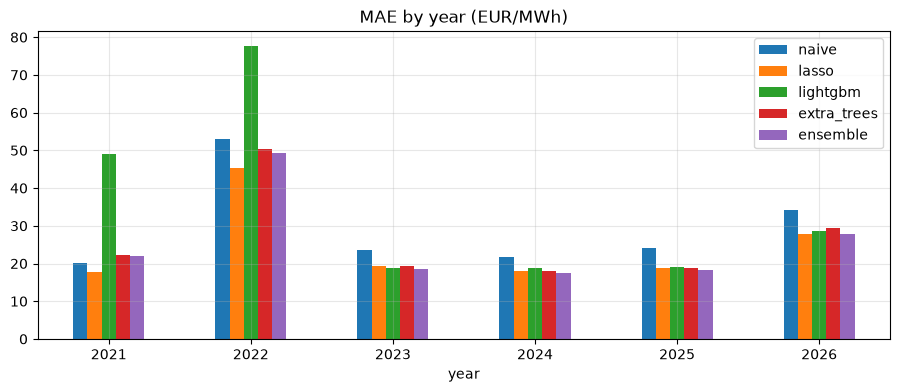

,naive / naive,lasso / naive,lightgbm / naive,extra_trees / naive,ensemble / naive
year,,,,,
2021,1.0,0.88,2.43,1.10,1.09
2022,1.0,0.86,1.47,0.95,0.93
2023,1.0,0.83,0.81,0.82,0.79
2024,1.0,0.83,0.86,0.83,0.81
2025,1.0,0.78,0.80,0.78,0.76
2026,1.0,0.81,0.84,0.85,0.81


In [3]:
yearly = mae_by_year(actual, predictions)
ax = yearly.plot.bar(rot=0, title="MAE by year (EUR/MWh)")
plt.show()
yearly.div(yearly["naive"], axis=0).round(2).rename(columns=lambda c: f"{c} / naive")

## Diebold–Mariano tests

Pairwise tests on the daily-averaged absolute-error differential. A negative statistic with p < 0.05 means `model_a` is significantly more accurate.

In [4]:
dm_table(actual, predictions).round(4)

,model_a,model_b,dm_stat,p_value
0,naive,lasso,10.0850,0.0000
1,naive,lightgbm,-7.2508,0.0000
2,naive,extra_trees,5.6012,0.0000
3,naive,ensemble,7.0367,0.0000
4,lasso,lightgbm,-14.6624,0.0000
5,lasso,extra_trees,-5.2036,0.0000
6,lasso,ensemble,-3.3970,0.0007
7,lightgbm,extra_trees,14.5233,0.0000
8,lightgbm,ensemble,16.2983,0.0000
9,extra_trees,ensemble,5.9668,0.0000


## Prediction intervals

Rolling conformal 90% intervals around the ensemble: for each delivery hour, the half-width is the 90% quantile of that hour's absolute errors over the previous 60 days. Coverage should be close to 90%; the width shows how uncertain each year was.

In [5]:
iv = conformal_intervals(actual, predictions["ensemble"])
y = actual.reindex(iv.index)
inside = (y >= iv["lower"]) & (y <= iv["upper"])
valid = iv["lower"].notna() & y.notna()
years = iv.index[valid].year
pd.DataFrame({
    "coverage": inside[valid].groupby(years).mean(),
    "mean_width": (iv["upper"] - iv["lower"])[valid].groupby(years).mean(),
}).round(3)

,coverage,mean_width
2021,0.808,71.613
2022,0.870,206.946
2023,0.898,91.218
2024,0.880,71.002
2025,0.882,79.077
2026,0.857,103.904


## 15-minute shape since the switch

Each model's 15-minute forecast is its hourly forecast plus a shared intra-hour shape (`quarter_hour.py`). Here, the same models with and without the shape, scored on the quarter-hours since 1 October 2025.

In [6]:
from fr_power.quarter_hour import broadcast_hourly

since = actual.index >= MTU_15MIN_START
flat = broadcast_hourly(hourly, actual.index).add_suffix("_hourly_flat")
point_metrics(actual[since], pd.concat([predictions, flat], axis=1)[since]).round(2)

,mae,rmse,median_ae,rmae_vs_naive
naive,32.47,49.43,20.04,1.00
lasso,26.33,36.65,19.63,0.81
lightgbm,26.86,37.30,20.40,0.83
extra_trees,27.36,37.29,21.37,0.84
ensemble,26.17,36.41,19.75,0.81
naive_hourly_flat,32.94,49.67,20.66,1.01
lasso_hourly_flat,27.19,37.71,20.33,0.84
lightgbm_hourly_flat,27.68,38.34,21.08,0.85
extra_trees_hourly_flat,28.14,38.33,22.08,0.87
ensemble_hourly_flat,27.00,37.48,20.37,0.83


## Error by hour of day

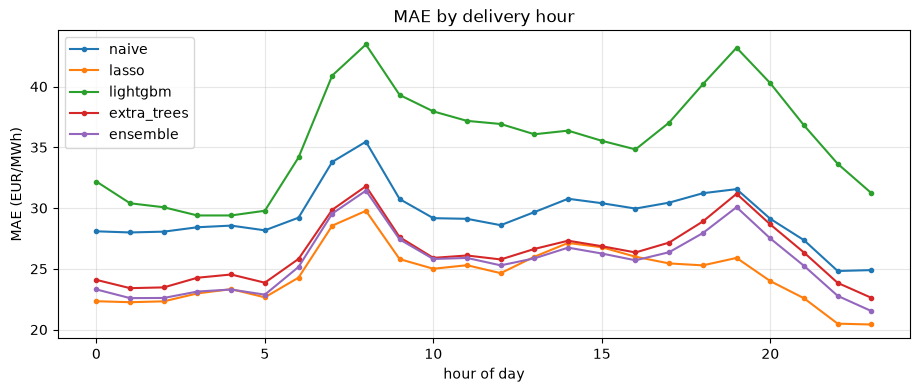

In [7]:
errors = df[predictions.columns].sub(df["actual"], axis=0).abs()
ax = errors.groupby(errors.index.hour).mean().plot(marker=".")
ax.set(xlabel="hour of day", ylabel="MAE (EUR/MWh)", title="MAE by delivery hour")
plt.show()

## Two sample weeks: winter and summer of the last full year

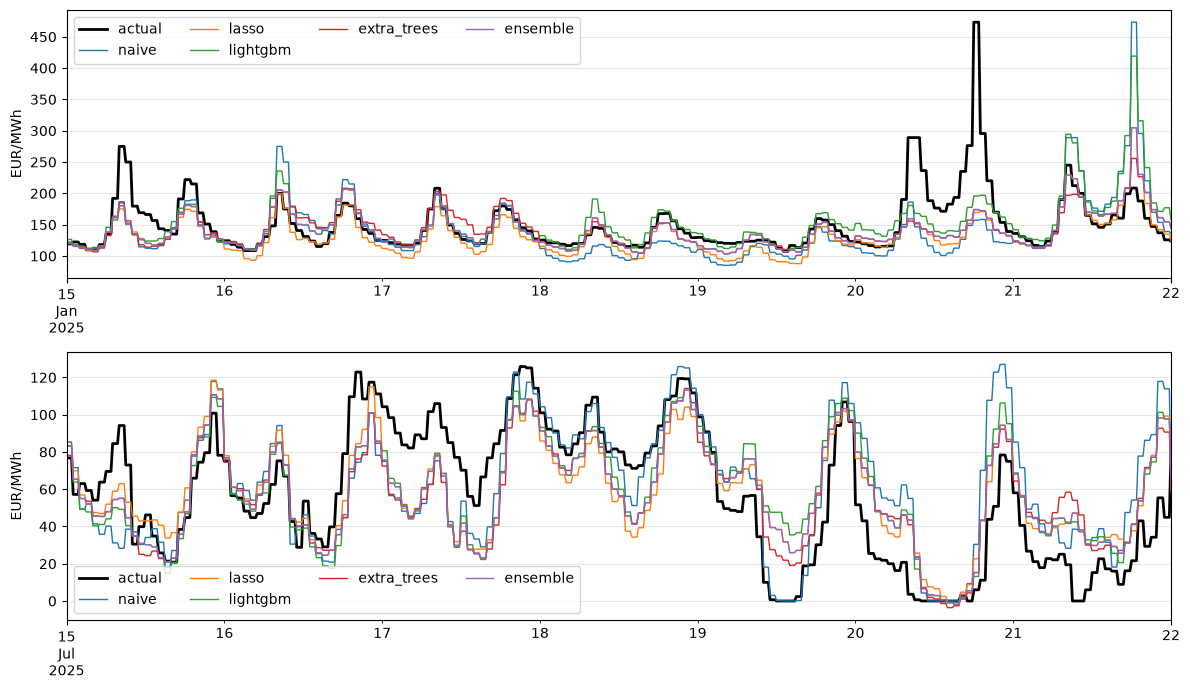

In [8]:
last_year = df.index.max().year - 1
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, start in zip(axes, [f"{last_year}-01-15", f"{last_year}-07-15"]):
    t0 = pd.Timestamp(start, tz=df.index.tz)
    week = df.loc[t0 : t0 + pd.Timedelta(days=7)]
    week["actual"].plot(ax=ax, color="black", linewidth=2, label="actual")
    week[predictions.columns].plot(ax=ax, linewidth=1)
    ax.set(ylabel="EUR/MWh", xlabel="")
    ax.legend(ncol=4)
plt.tight_layout()
plt.show()

## What drives LightGBM?

One fit on the last two years of data (not walk-forward, illustration only); importance = total split gain.

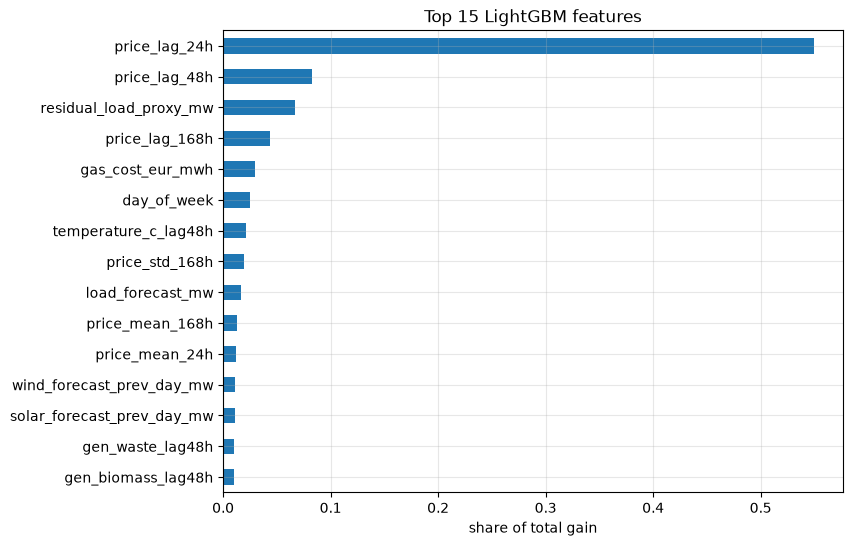

In [9]:
recent = matrix[matrix.index >= matrix.index.max() - pd.Timedelta(days=730)].dropna(subset=[TARGET])
model = LightGBMForecaster(cfg.models.lightgbm, random_seed=cfg.random_seed)
model.fit(recent[feature_columns(matrix)], recent[TARGET])
importance = pd.Series(
    model.model_.booster_.feature_importance("gain"), index=feature_columns(matrix)
).sort_values()
ax = (importance / importance.sum()).tail(15).plot.barh(figsize=(8, 6))
ax.set(xlabel="share of total gain", title="Top 15 LightGBM features")
plt.show()